In [2]:
import sys
import os
import xarray as xr
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))    # So can access functions in isca_tools which is in home/Isca directory
import isca_tools
import numpy as np
from isca_tools.utils import area_weighting
from isca_tools.plot import plot_spin_up
from isca_tools.utils.radiation import frierson_net_toa_sw_dwn
from isca_tools.utils.land import get_land_coords, get_ocean_coords

In [38]:
# Load dataset
exp_name = os.getcwd().replace(f"{os.environ['GFDL_WORK']}jobs/", '')
# exp_name = 'tau_sweep/aquaplanet/depth=1/k=1'
ds = {'all': isca_tools.load_dataset(exp_name)[['ps', 't_surf', 'swdn_toa', 'olr', 'swdn_sfc']]}
namelist = isca_tools.load_namelist(exp_name)  # Need this for albedo_value
albedo = namelist['mixed_layer_nml']['albedo_value']
tau_sw = namelist['two_stream_gray_rad_nml']['atm_abs']
ds['all']['sw_net_toa'] = frierson_net_toa_sw_dwn(ds['all'].swdn_toa, ds['all'].ps, albedo, tau_sw)     # calculate from absorbed
reflected_sw = albedo / (1 - albedo) * ds['all'].swdn_sfc
ds['all']['sw_net_toa2'] = ds['all'].swdn_toa - reflected_sw                                            # calculate from reflected    
ds['all']['toa_imbalance'] = ds['all']['sw_net_toa2'] - ds['all']['olr']

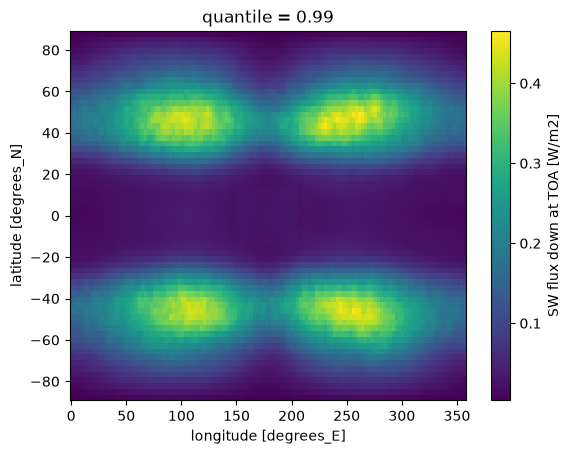

In [ ]:
# Check definitions of SW at TOA, seem very similar, although clearly some preferred regions where discrepancy larger - must be impacted by land location.
var = np.abs(ds['all']['sw_net_toa'] - ds['all']['sw_net_toa2'])
var = var.load()
np.abs(var).quantile(0.99, dim='time').plot()

In [39]:
lon_surf = {'land': get_land_coords(f"{os.getcwd()}/namelist.nml", f"{os.getcwd()}/land.nc")[1], 
            'ocean': get_ocean_coords(f"{os.getcwd()}/namelist.nml", f"{os.getcwd()}/land.nc")[1]}
for key in lon_surf:
    ds[key] = ds['all'].isel(lon=np.where(np.isin(ds['all'].lon, np.unique(lon_surf[key])))[0])

In [40]:
n_year_days = 360
n_years = int(ds['all'].time.size / n_year_days)
ds_annual_mean = {}
for key in ds:
    ds_annual_mean[key] = xr.concat([ds[key].sel(time=slice(ds['all'].time.values[0]+i*n_year_days, ds['all'].time.values[0]+(i+1)*n_year_days)).mean(dim='time', keepdims=True) for i in range(n_years)], dim='time')
    ds_annual_mean[key] = ds_annual_mean[key].load()
    # ds_annual_mean[key]['short_wave_net'] = frierson_net_toa_sw_dwn(ds_annual_mean[key].swdn_toa, ds_annual_mean[key].ps, albedo, tau_sw)
    # ds_annual_mean[key]['short_wave_net2'] = albedo / (1 - albedo) * ds.swdn_sfc

(-3000.0, 1000.0)

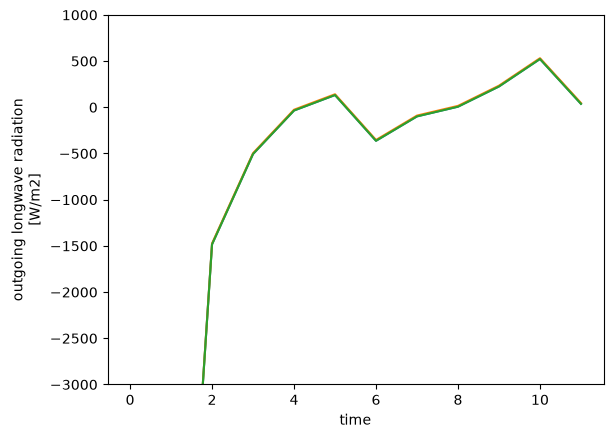

In [51]:
# Plot TOA imbalnce with different definitions of imbalance, all show the same.
area_weighting(-ds_annual_mean['all'].toa_imbalance).sum(dim=['lon', 'lat']).plot()
area_weighting(-ds_annual_mean['all']['sw_net_toa'] + ds_annual_mean['all']['olr']).sum(dim=['lon', 'lat']).plot()
area_weighting(-ds_annual_mean['all']['sw_net_toa2'] + ds_annual_mean['all']['olr']).sum(dim=['lon', 'lat']).plot()
plt.gca().set_ylim(-3000, 1000)

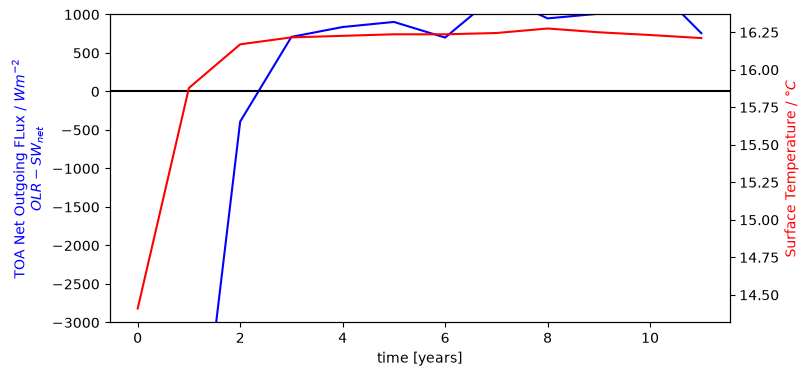

In [55]:
# Plot spinup time for each depth value
fig, ax = plt.subplots(1,1, figsize=(8, 4))
key = 'ocean'     # or just ocean, just land to check different heat capacities
# plot_spin_up(ds_annual_mean[key].olr, ds_annual_mean[key].short_wave_net, ds_annual_mean[key].t_surf, ax)
plot_spin_up(ds_annual_mean[key].olr, ds_annual_mean[key].sw_net_toa2, ds_annual_mean[key].t_surf, ax)
ax.set_ylim(-3000, 1000)
ax.axhline(0, color='k')
ax.set_xlabel('time [years]')
plt.show()

(3500.0, 4200.0)

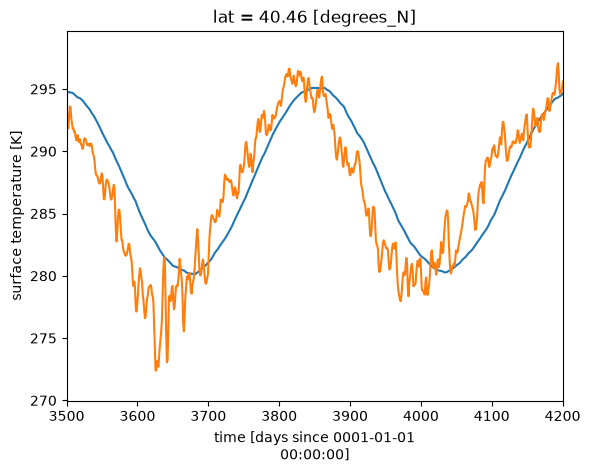

In [7]:
ds['ocean'].t_surf.mean(dim='lon').sel(lat=40, method='nearest').plot()
ds['land'].t_surf.mean(dim='lon').sel(lat=40, method='nearest').plot()
plt.gca().set_xlim(3500, 4200)